In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)

yield_train = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_selected",
    conn
)

conn.close()

print("Dataset shape:", yield_train.shape)
print("Columns:", yield_train.columns.tolist())

display(yield_train.head())

Dataset shape: (10000, 11)
Columns: ['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall', 'yield']


,NDVI_Temperature,OrganicMatter_Sand,Temperature_Rainfall,sand_pct,NDVI_Rainfall,soil_ph,organic_matter,Humidity_Rainfall,Temperature_Humidity,rainfall,yield
0,11.592,110.656,2777.04,41.6,50.692,6.25,2.66,7714.0,1764.0,110.2,4105.8
1,15.871,147.132,3397.47,40.2,74.517,6.70,3.66,9851.4,2098.2,126.3,4247.8
2,17.664,138.000,3019.44,40.0,70.016,7.21,3.45,7220.4,1821.6,109.4,4021.8
3,18.352,141.112,4596.88,56.9,96.286,5.73,2.48,12268.7,2338.4,155.3,4326.8
4,15.500,110.466,4315.00,30.6,107.012,6.88,3.61,13808.0,2000.0,172.6,3708.0


In [2]:
if "yield" not in yield_train.columns:
    raise ValueError("Target column 'yield' is missing.")

# Separate features and target
X = yield_train.drop(columns=["yield"])
y = yield_train["yield"]

# Select numerical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

if not numeric_features:
    raise ValueError("No numerical input features were found.")

print("Number of records:", len(yield_train))
print("Number of numerical features:", len(numeric_features))
print("\nNumerical features:")
print(numeric_features)

print("\nMissing values:")
display(yield_train.isnull().sum().to_frame(name="Missing Values"))

print("\nData types:")
display(yield_train.dtypes.to_frame(name="Data Type"))

Number of records: 10000
Number of numerical features: 10

Numerical features:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall']

Missing values:


,Missing Values
NDVI_Temperature,0
OrganicMatter_Sand,0
Temperature_Rainfall,0
sand_pct,0
NDVI_Rainfall,0
soil_ph,0
organic_matter,0
Humidity_Rainfall,0
Temperature_Humidity,0
rainfall,0



Data types:


,Data Type
NDVI_Temperature,float64
OrganicMatter_Sand,float64
Temperature_Rainfall,float64
sand_pct,float64
NDVI_Rainfall,float64
soil_ph,float64
organic_matter,float64
Humidity_Rainfall,float64
Temperature_Humidity,float64
rainfall,float64


In [3]:
# Calculate correlation between each numerical feature and yield
yield_correlations = (
    yield_train[numeric_features + ["yield"]]
    .corr(numeric_only=True)["yield"]
    .drop("yield")
    .sort_values(ascending=False)
)

print("Feature correlation with yield:")
display(yield_correlations.to_frame(name="Correlation"))

Feature correlation with yield:


,Correlation
rainfall,0.016959
Humidity_Rainfall,0.015530
Temperature_Rainfall,0.010961
NDVI_Rainfall,0.008303
soil_ph,0.007098
organic_matter,0.002207
sand_pct,-0.003933
OrganicMatter_Sand,-0.004481
NDVI_Temperature,-0.006547
Temperature_Humidity,-0.008135


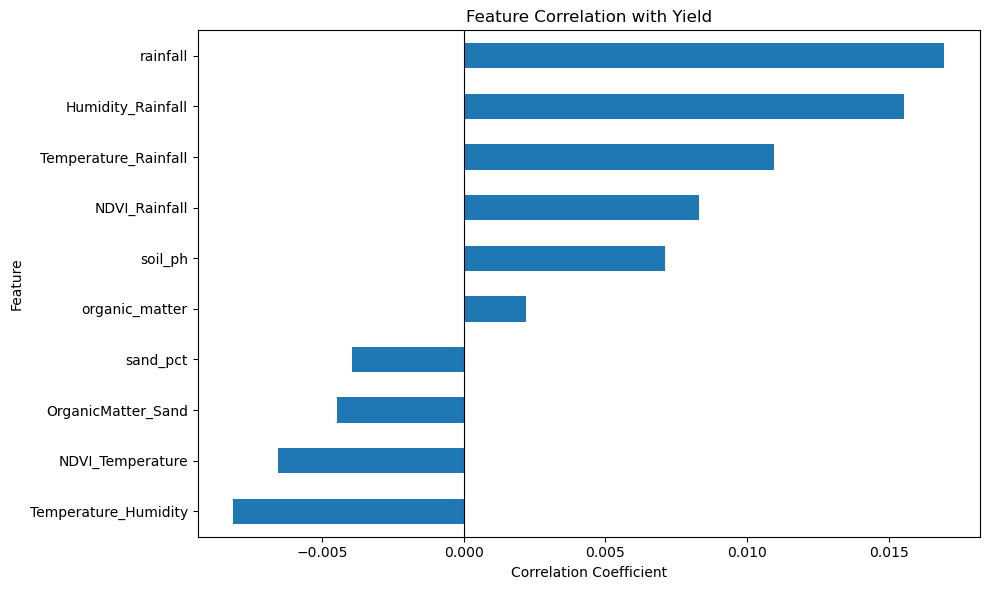

In [4]:
plt.figure(figsize=(10, 6))

yield_correlations.sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Yield")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

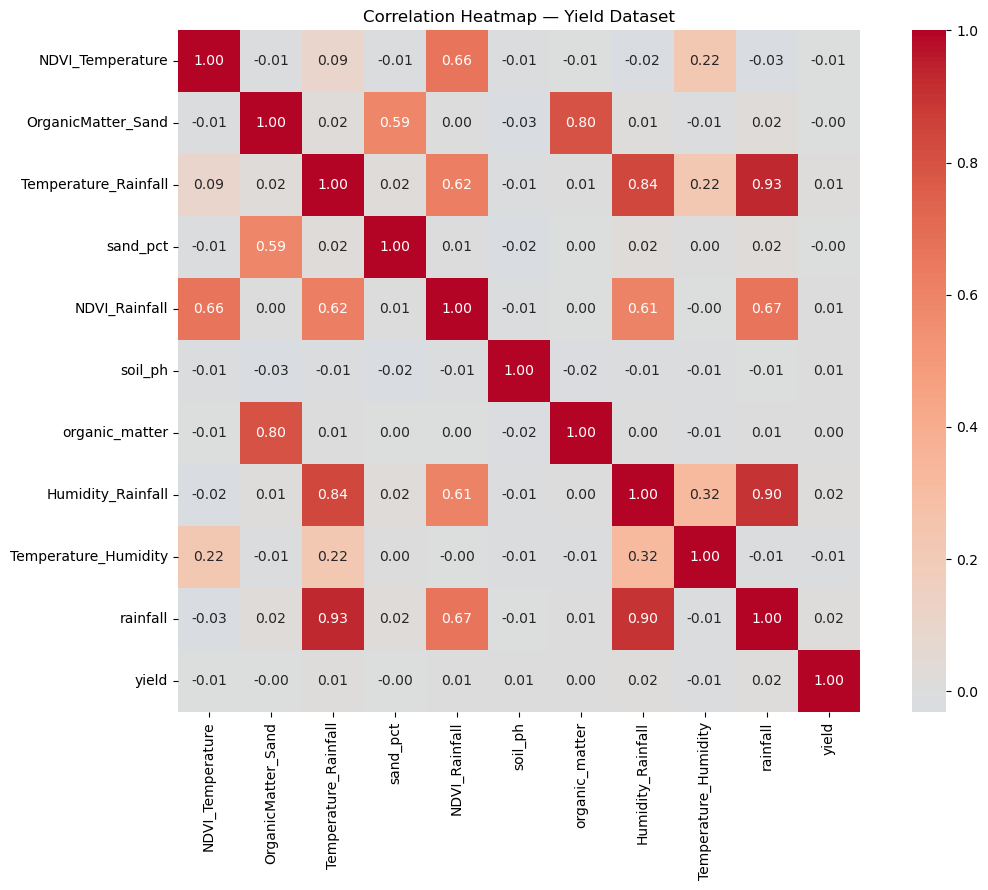

In [5]:
correlation_matrix = yield_train[
    numeric_features + ["yield"]
].corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap — Yield Dataset")
plt.tight_layout()
plt.show()

Features selected for scatter plots:
['rainfall', 'Humidity_Rainfall', 'Temperature_Rainfall']


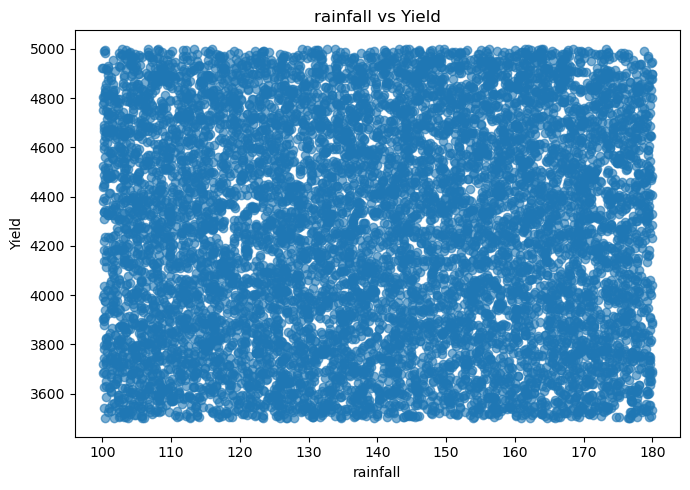

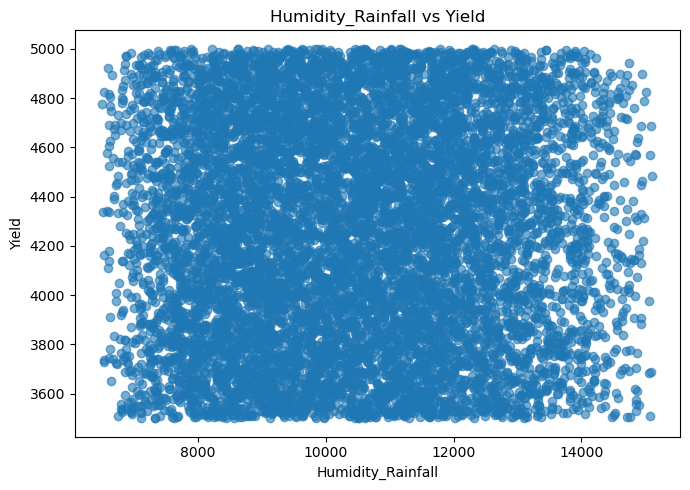

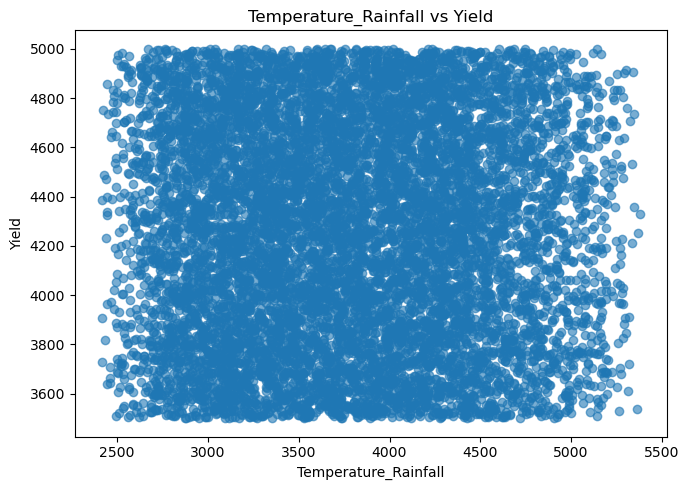

In [6]:
top_features = (
    yield_correlations.abs()
    .sort_values(ascending=False)
    .head(3)
    .index.tolist()
)

print("Features selected for scatter plots:")
print(top_features)

for feature in top_features:
    plot_data = yield_train[[feature, "yield"]].dropna()

    plt.figure(figsize=(7, 5))

    plt.scatter(
        plot_data[feature],
        plot_data["yield"],
        alpha=0.6
    )

    plt.title(f"{feature} vs Yield")
    plt.xlabel(feature)
    plt.ylabel("Yield")
    plt.tight_layout()
    plt.show()

In [7]:
feature_corr = X[numeric_features].corr(numeric_only=True)

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Correlation"] >= 0.90
].sort_values(
    "Absolute Correlation",
    ascending=False
)

print("Feature pairs with absolute correlation >= 0.90:")

if high_corr_pairs.empty:
    print("No highly correlated feature pairs found at this threshold.")
else:
    display(high_corr_pairs)

Feature pairs with absolute correlation >= 0.90:


,Feature 1,Feature 2,Correlation,Absolute Correlation
23,Temperature_Rainfall,rainfall,0.928872,0.928872
43,Humidity_Rainfall,rainfall,0.902312,0.902312


In [8]:
import os

output_dir = "stage14_outputs"
os.makedirs(output_dir, exist_ok=True)

yield_correlations.to_csv(
    os.path.join(output_dir, "yield_feature_correlations.csv"),
    header=["Correlation"]
)

correlation_matrix.to_csv(
    os.path.join(output_dir, "yield_correlation_matrix.csv")
)

high_corr_pairs.to_csv(
    os.path.join(output_dir, "highly_correlated_features.csv"),
    index=False
)

print("Stage 14 outputs saved in:", output_dir)

Stage 14 outputs saved in: stage14_outputs
